In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/Telco-Customer-Churn.csv")


In [ ]:
print(df.shape)

(7043, 21)


In [ ]:
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print(df["TotalCharges"].isnull().sum())

11


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(df["TotalCharges"].isnull().sum())

0


In [ ]:
print("Total Customers:", df["customerID"].nunique())

print("Churned Customers:",(df["Churn"] == "Yes").sum())

print("Retained Customers:",(df["Churn"] == "No").sum())

churn_rate = (df["Churn"] == "Yes").mean() * 100

print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %


In [ ]:
contract_analysis = df.groupby("Contract").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=("Churn",
                       lambda x: (x == "Yes").sum())
)

contract_analysis["Churn_Rate"] = (
    contract_analysis["Churned_Customers"] /
    contract_analysis["Total_Customers"] * 100
)

print(contract_analysis.round(2))

                Total_Customers  Churned_Customers  Churn_Rate
Contract                                                      
Month-to-month             3875               1655       42.71
One year                   1473                166       11.27
Two year                   1695                 48        2.83


In [ ]:
payment_analysis = df.groupby("PaymentMethod").agg(
    Total_Customers=("customerID", "count"),
    Churned=("Churn",
             lambda x: (x == "Yes").sum())
)

payment_analysis["Churn_Rate"] = (
    payment_analysis["Churned"] /
    payment_analysis["Total_Customers"] * 100
)

print(payment_analysis.round(2))

                           Total_Customers  Churned  Churn_Rate
PaymentMethod                                                  
Bank transfer (automatic)             1544      258       16.71
Credit card (automatic)               1522      232       15.24
Electronic check                      2365     1071       45.29
Mailed check                          1612      308       19.11


In [ ]:
print(
    df.groupby("Churn")["tenure"]
      .mean()
      .round(2)
)

Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


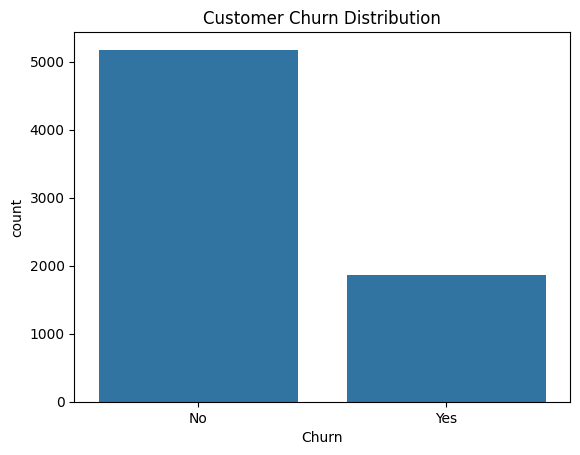

In [ ]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

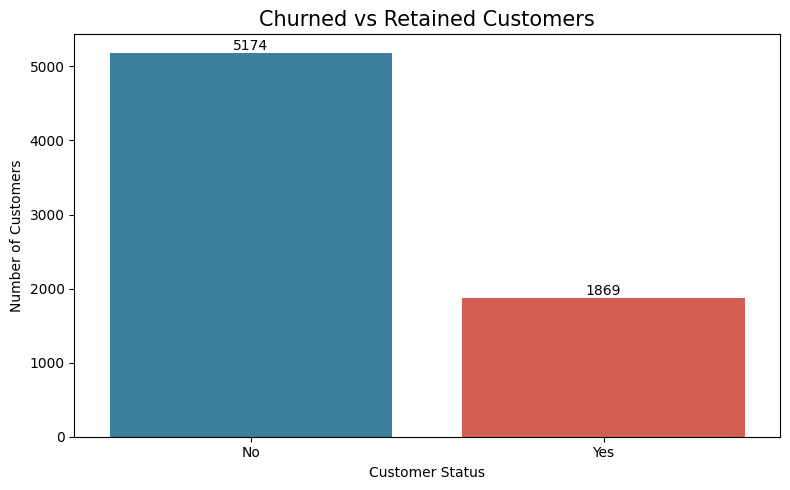

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette=["#2E86AB", "#E74C3C"],
    legend=False
)

plt.title("Churned vs Retained Customers", fontsize=15)
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for container in plt.gca().containers:
    plt.bar_label(container)

plt.tight_layout()
plt.show()

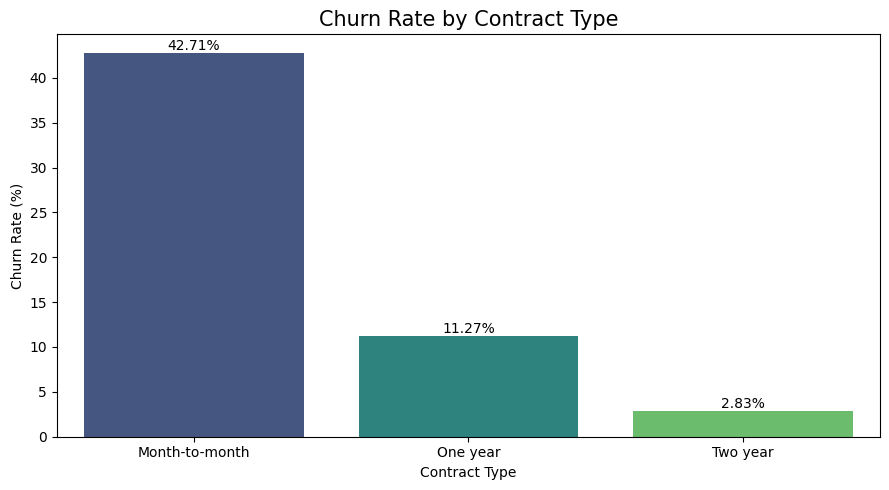

         Contract  Total_Customers  Churned_Customers  Churn_Rate
0  Month-to-month             3875               1655       42.71
1        One year             1473                166       11.27
2        Two year             1695                 48        2.83


In [ ]:
contract_churn = (
    df.groupby("Contract")
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

contract_churn["Churn_Rate"] = (
    contract_churn["Churned_Customers"] /
    contract_churn["Total_Customers"] * 100
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn_Rate",
    hue="Contract",
    palette="viridis",
    legend=False
)

plt.title("Churn Rate by Contract Type", fontsize=15)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

print(contract_churn.round(2))

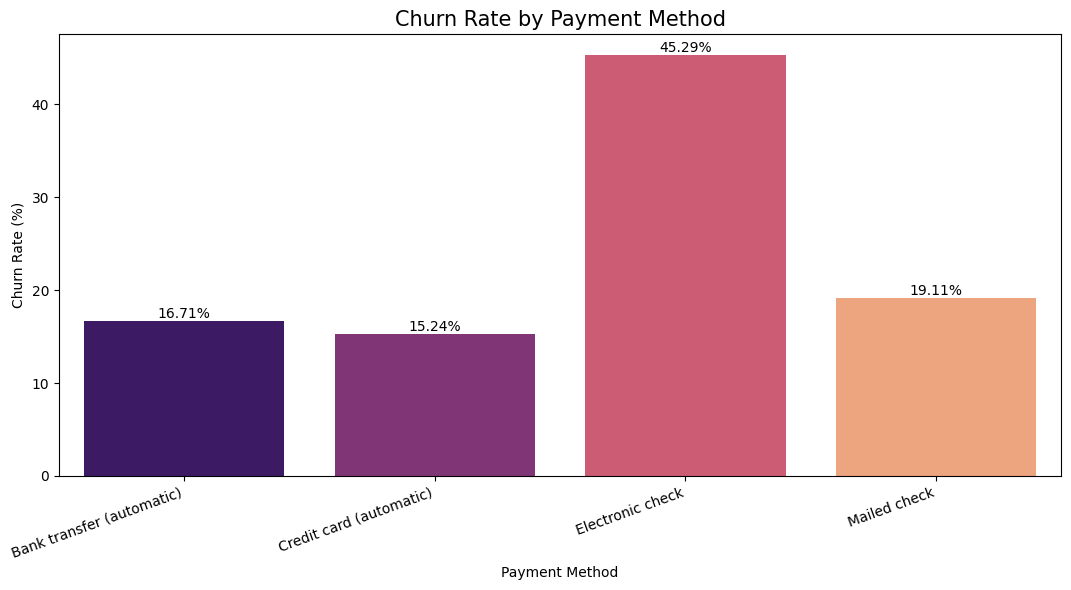

               PaymentMethod  Total_Customers  Churned_Customers  Churn_Rate
0  Bank transfer (automatic)             1544                258       16.71
1    Credit card (automatic)             1522                232       15.24
2           Electronic check             2365               1071       45.29
3               Mailed check             1612                308       19.11


In [ ]:
payment_churn = (
    df.groupby("PaymentMethod")
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

payment_churn["Churn_Rate"] = (
    payment_churn["Churned_Customers"] /
    payment_churn["Total_Customers"] * 100
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=payment_churn,
    x="PaymentMethod",
    y="Churn_Rate",
    hue="PaymentMethod",
    palette="magma",
    legend=False
)

plt.title("Churn Rate by Payment Method", fontsize=15)
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

print(payment_churn.round(2))

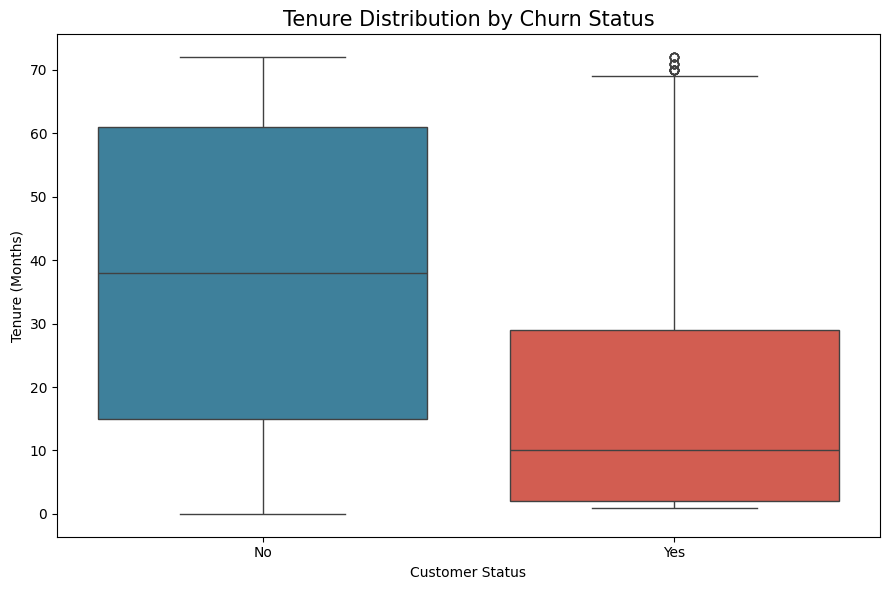

In [ ]:
plt.figure(figsize=(9, 6))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette=["#2E86AB", "#E74C3C"],
    legend=False
)

plt.title("Tenure Distribution by Churn Status", fontsize=15)
plt.xlabel("Customer Status")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()